# Navier-Stokes with the IPCS scheme

The incompressible Navier-Stokes equations,

$$ \partial_t u + (u\cdot\nabla)u - \nu\Delta u + \nabla p = 0, \qquad \nabla\cdot u = 0, $$

solved with the incremental pressure correction scheme (IPCS), as in the Navier-Stokes
chapter of the [FEniCSx tutorial](https://jsdokken.com/dolfinx-tutorial/) and the
time-dependent flow demos in the [DOLFINx demos](https://docs.fenicsproject.org/dolfinx/main/python/demos.html).
Each time step $t_n \to t_{n+1}$ consists of three linear problems:

1. a *tentative velocity* $u^\ast$ from the momentum equation with the old pressure $p^n$ and a
   Crank-Nicolson average $U = (u^n + u^\ast)/2$, with $u^n$ as convecting velocity,
2. a *pressure Poisson problem* for $p^{n+1}$, which makes the corrected velocity divergence free,
   $\;\int \nabla p^{n+1}\cdot\nabla q = \int \nabla p^{n}\cdot\nabla q - \tfrac1{\Delta t}\int (\nabla\cdot u^\ast)\, q$,
3. a *velocity correction* $u^{n+1} = u^\ast - \Delta t\,\nabla(p^{n+1} - p^n)$ in the mass-matrix sense.

The step-1 matrix contains $u^n$ and has to be reassembled, whereas the matrices of steps 2 and 3 never
change.  We tell the solver so with `constant_jacobian=True`; it then factorises them once.
The scheme is first order in time, which is sufficient for the two examples here:
(a) a channel flow whose steady state is known exactly, (b) the flow around a cylinder.
The front end follows the Firedrake API, and the code below is written in that style.

## The scheme as a function

The stress $\sigma(u,p) = 2\nu\,\varepsilon(u) - pI$ is used in the momentum equation, so that the outflow
condition "natural boundary condition with $p=0$" is consistent: only the pressure of the
previous step enters the boundary term in step 1.

In [1]:
from ngsufl import *
import numpy as np


def ipcs(mesh, nu, dt, nsteps, inlet_velocity, inlet, outlet, walls, callback=None):
    V = VectorFunctionSpace(mesh, "CG", 2)
    Q = FunctionSpace(mesh, "CG", 1)
    u, v = TrialFunction(V), TestFunction(V)
    p, q = TrialFunction(Q), TestFunction(Q)

    u_n, u_s, u_new = Function(V, name="u_n"), Function(V), Function(V, name="u")
    p_n, p_new = Function(Q, name="p_n"), Function(Q, name="p")

    n = FacetNormal(mesh)
    eps = lambda w: sym(nabla_grad(w))
    sigma = lambda w, r: 2 * nu * eps(w) - r * Identity(len(w))
    U = 0.5 * (u_n + u)

    F1 = (dot((u - u_n) / dt, v) * dx + dot(dot(u_n, nabla_grad(U)), v) * dx
          + inner(sigma(U, p_n), eps(v)) * dx + dot(p_n * n, v) * ds(outlet)
          - dot(nu * nabla_grad(U) * n, v) * ds(outlet))
    a1, L1 = lhs(F1), rhs(F1)

    a2 = dot(grad(p), grad(q)) * dx
    L2 = dot(grad(p_n), grad(q)) * dx - (1 / dt) * div(u_s) * q * dx

    a3 = dot(u, v) * dx
    L3 = dot(u_s, v) * dx - dt * dot(grad(p_new - p_n), v) * dx

    bcu = [DirichletBC(V, inlet_velocity, inlet), DirichletBC(V, Constant((0.0, 0.0)), walls)]
    bcp = [DirichletBC(Q, Constant(0.0), outlet)]

    step1 = LinearVariationalSolver(LinearVariationalProblem(a1, L1, u_s, bcs=bcu))
    step2 = LinearVariationalSolver(LinearVariationalProblem(a2, L2, p_new, bcs=bcp, constant_jacobian=True))
    step3 = LinearVariationalSolver(LinearVariationalProblem(a3, L3, u_new, constant_jacobian=True))

    for k in range(nsteps):
        step1.solve()
        step2.solve()
        step3.solve()
        u_n.assign(u_new)
        p_n.assign(p_new)
        if callback:
            callback(k, u_new, p_new)
    return u_new, p_new

## (a) Channel flow

In the channel $(0,2)\times(0,1)$ the boundaries are numbered as in Firedrake: 1 ($x=0$, inlet),
2 ($x=2$, outlet), 3 ($y=0$) and 4 ($y=1$), the walls.  The Poiseuille profile $u = (4y(1-y), 0)$ with
$p = 8\nu(2 - x)$ is an exact steady solution.  We prescribe it at the inlet, no slip at the walls and $p=0$
at the outlet, start from rest and march until the flow is steady.  Since the exact solution lies in
the finite element space, the discrete steady state should reproduce it closely.

In [2]:
mesh = RectangleMesh(16, 8, 2.0, 1.0)
x, y = SpatialCoordinate(mesh)
nu = 0.1
u_ex = as_vector((4 * y * (1 - y), 0.0))
p_ex = 8 * nu * (2 - x)

uh, ph = ipcs(mesh, nu, dt=0.02, nsteps=100, inlet_velocity=u_ex,
              inlet=1, outlet=2, walls=(3, 4))

print("t = 2.0")
print("velocity L2 error:", errornorm(u_ex, uh))
print("pressure L2 error:", errornorm(p_ex, ph))

t = 2.0
velocity L2 error: 1.5955955832576407e-06
pressure L2 error: 4.620060352907765e-05


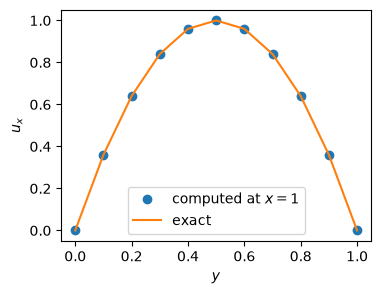

In [3]:
import matplotlib.pyplot as plt

xs = np.linspace(0, 1, 11)
fig, ax = plt.subplots(figsize=(4, 3))
ax.plot(xs, [uh.at(1.0, y)[0] for y in xs], "o", label="computed at $x=1$")
ax.plot(xs, 4 * xs * (1 - xs), "-", label="exact")
ax.set_xlabel("$y$"); ax.set_ylabel("$u_x$"); ax.legend();

## (b) Flow past a cylinder

This is the geometry of the DFG benchmark 2D-1 of Schäfer and Turek: a channel $2.2 \times 0.41$ with a
cylinder of radius $0.05$ centred at $(0.2, 0.2)$, viscosity $\nu = 10^{-3}$ and the parabolic inflow
$u_x = 4 U_m\, y(H-y)/H^2$ with $U_m = 0.3$.  The Reynolds number based on the mean velocity
$0.2$ and the diameter is 20, and the flow becomes steady.

The geometry is built with `netgen.occ` by subtracting the disk from the rectangle.  The
edges receive names, which become boundary names of the mesh and are used directly in the
boundary conditions and measures.  Names are an ngsufl extra; Firedrake would use the
numbers of the boundary markers (here the 1-based NGSolve boundary index).  After meshing, `curve(3)` makes the mesh elements
curved, so that the circle is represented accurately even on this coarse mesh.

In [4]:
from netgen.occ import *

H = 0.41
channel = Rectangle(2.2, H).Face()
channel.edges.Min(X).name = "inlet"
channel.edges.Max(X).name = "outlet"
channel.edges.Min(Y).name = "wall"
channel.edges.Max(Y).name = "wall"
cylinder = Circle((0.2, 0.2), 0.05).Face()
cylinder.edges.name = "cylinder"
cylinder.edges.maxh = 0.005

fluid = channel - cylinder
mesh = Mesh(OCCGeometry(fluid, dim=2).GenerateMesh(maxh=0.04)).curve(3)
print(mesh.boundary_names, "-", mesh.ngs.ne, "elements")

('wall', 'inlet', 'outlet', 'cylinder') - 1687 elements


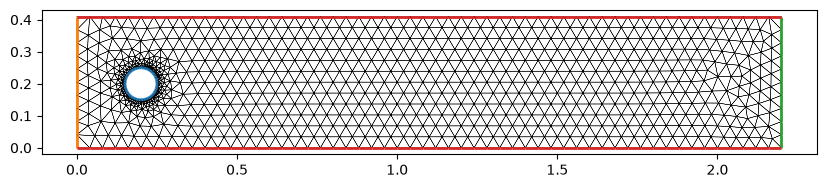

In [5]:
from ngsufl.pyplot import tripcolor, triplot

fig, axes = plt.subplots(figsize=(10, 2))
triplot(mesh, axes=axes, interior_kw={"linewidth": 0.3})
axes.set_aspect("equal");

We march to $t=8$ with $\Delta t = 0.02$.  The force on the cylinder is evaluated from the
discrete solution as the boundary integral of $-(2\nu\,\varepsilon(u) - pI)\, n$ over the
cylinder, where $n$ is the `FacetNormal`, pointing out of the fluid.  This gives the drag
and lift coefficients $c = 2F/(\bar U^2 D)$.  The benchmark reports $c_D = 5.5795$, $c_L = 0.0106$ and a pressure
difference of $0.1175$ between the front and rear of the cylinder.

In [6]:
import time

x, y = SpatialCoordinate(mesh)
Um = 0.3
inflow = as_vector((4 * Um * y * (H - y) / H**2, 0.0))
nu = 1e-3

t0 = time.time()
uh, ph = ipcs(mesh, nu, dt=0.02, nsteps=400, inlet_velocity=inflow,
              inlet="inlet", outlet="outlet", walls="wall|cylinder")
print(f"{time.time() - t0:.1f} s for 400 steps")

n = FacetNormal(mesh)
force = -(2 * nu * sym(grad(uh)) * n - ph * n)
Ubar, D = 0.2, 0.1
cD = 2 / (Ubar**2 * D) * assemble(force[0] * ds("cylinder"))
cL = 2 / (Ubar**2 * D) * assemble(force[1] * ds("cylinder"))
dp = ph.at(0.15, 0.2) - ph.at(0.25, 0.2)
print(f"drag  c_D = {cD:.4f}   (reference 5.5795)")
print(f"lift  c_L = {cL:.4f}   (reference 0.0106)")
print(f"pressure difference = {dp:.4f}   (reference 0.1175)")

9.8 s for 400 steps
drag  c_D = 5.5813   (reference 5.5795)
lift  c_L = 0.0143   (reference 0.0106)
pressure difference = 0.1169   (reference 0.1175)


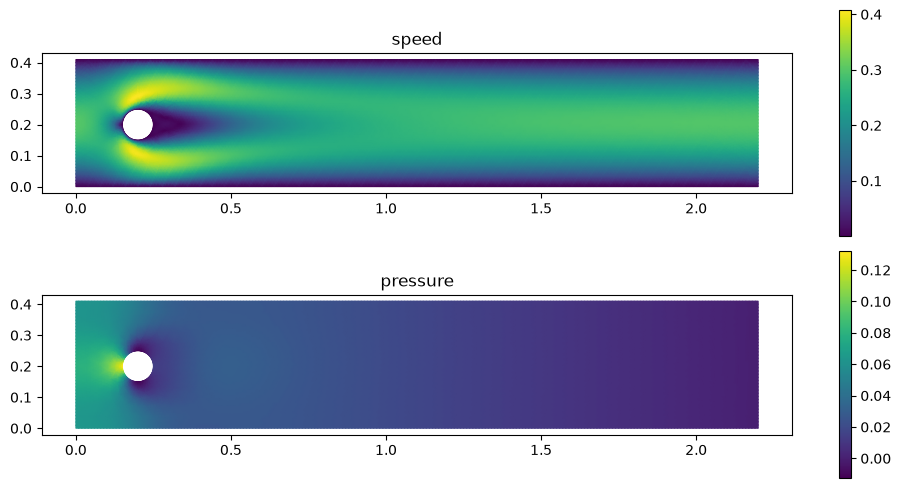

In [7]:
fig, axs = plt.subplots(2, 1, figsize=(10, 5))
for axes, field, title in zip(axs, (uh, ph), ("speed", "pressure")):
    colors = tripcolor(field, axes=axes)
    fig.colorbar(colors, ax=axes)
    axes.set_aspect("equal")
    axes.set_title(title)
fig.tight_layout();